# Predictive Customer Churn Classifier (Random Forest & XGBoost)
**Goal:** predict telecom customer churn, handle class imbalance with SMOTE, and reach ROC-AUC > 0.80.

**Pipeline:** load data → clean `TotalCharges` → train/test split → OneHotEncoder + SMOTE (inside the CV pipeline, so no leakage) → Random Forest & XGBoost with cross-validation → ROC curves, confusion matrices, top-10 feature importances.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay, classification_report
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
warnings.filterwarnings("ignore")
RS = 42

## 1. Load the Telco Customer Churn dataset

In [2]:
df = pd.read_csv("Telco-Customer-Churn.csv")   # starter file from the task page
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Convert `TotalCharges` to numeric and handle nulls
`TotalCharges` is stored as text; 11 rows are blank spaces (customers with `tenure = 0`, not yet billed), so they are set to 0.

In [3]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Nulls before fill:", df["TotalCharges"].isna().sum())
print(df.loc[df["TotalCharges"].isna(), "tenure"].unique())   # all tenure == 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)
df = df.drop(columns="customerID")
df["Churn"] = (df["Churn"] == "Yes").astype(int)
print(df["Churn"].value_counts(), "\nChurn rate: %.1f%%" % (df["Churn"].mean()*100))

Nulls before fill: 11
[0]
Churn
0    5174
1    1869
Name: count, dtype: int64 
Churn rate: 26.5%


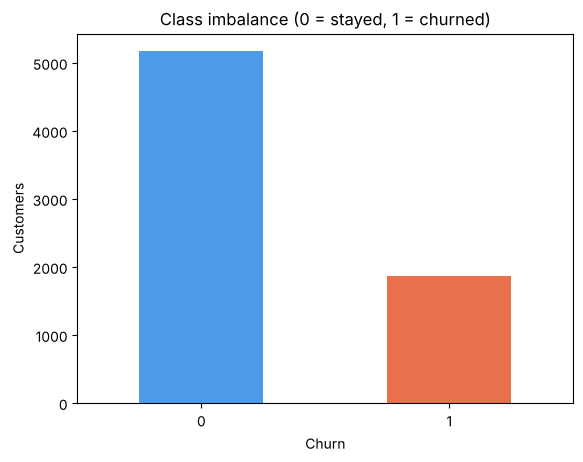

In [4]:
df["Churn"].value_counts().plot(kind="bar", color=["#4c9be8", "#e8704c"], rot=0)
plt.title("Class imbalance (0 = stayed, 1 = churned)"); plt.ylabel("Customers"); plt.show()

## 3. Preprocess and split

In [5]:
X, y = df.drop(columns="Churn"), df["Churn"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RS)

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in X.columns if c not in num_cols]
pre = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)

## 4. Balance classes with SMOTE and train both models with 5-fold cross-validation
SMOTE sits inside the `imblearn` Pipeline, so it is applied only to the training folds and the validation folds stay untouched.

In [6]:
rf_pipe = Pipeline([
    ("pre", pre), ("smote", SMOTE(random_state=RS)),
    ("clf", RandomForestClassifier(n_estimators=300, max_depth=12, min_samples_leaf=3, n_jobs=-1, random_state=RS)),
])
xgb_pipe = Pipeline([
    ("pre", pre), ("smote", SMOTE(random_state=RS)),
    ("clf", XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
                          colsample_bytree=0.8, eval_metric="logloss", n_jobs=-1, random_state=RS)),
])
models = {"Random Forest": rf_pipe, "XGBoost": xgb_pipe}

for name, m in models.items():
    s = cross_val_score(m, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=1)
    print(f"{name:14s} CV ROC-AUC: {s.mean():.4f} ± {s.std():.4f}")
    m.fit(X_train, y_train)

Random Forest  CV ROC-AUC: 0.8392 ± 0.0080


XGBoost        CV ROC-AUC: 0.8426 ± 0.0096


## 5. Evaluate on the held-out test set

Random Forest  test ROC-AUC: 0.8350  PASS (>0.80)
XGBoost        test ROC-AUC: 0.8402  PASS (>0.80)


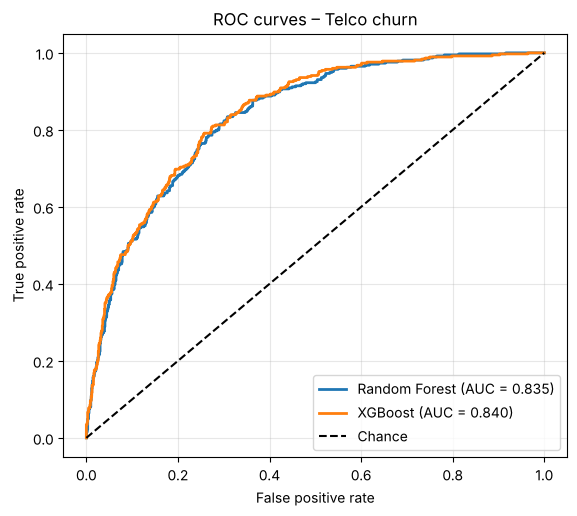

In [7]:
probs = {n: m.predict_proba(X_test)[:, 1] for n, m in models.items()}
aucs = {n: roc_auc_score(y_test, p) for n, p in probs.items()}
for n, a in aucs.items():
    print(f"{n:14s} test ROC-AUC: {a:.4f}  {'PASS (>0.80)' if a > 0.80 else 'below target'}")

plt.figure(figsize=(6.5, 5.5))
for n, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, lw=2, label=f"{n} (AUC = {aucs[n]:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves – Telco churn"); plt.legend(loc="lower right"); plt.grid(alpha=.3); plt.show()

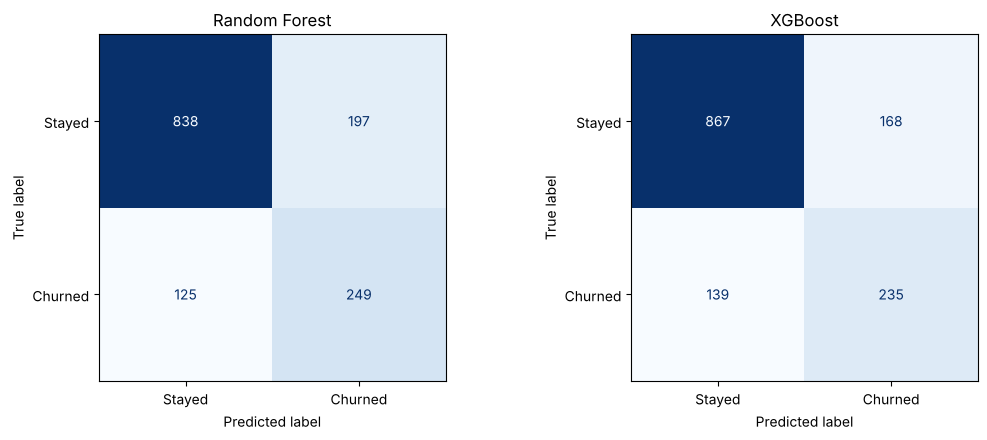

--- Random Forest ---
              precision    recall  f1-score   support

      Stayed       0.87      0.81      0.84      1035
     Churned       0.56      0.67      0.61       374

    accuracy                           0.77      1409
   macro avg       0.71      0.74      0.72      1409
weighted avg       0.79      0.77      0.78      1409

--- XGBoost ---
              precision    recall  f1-score   support

      Stayed       0.86      0.84      0.85      1035
     Churned       0.58      0.63      0.60       374

    accuracy                           0.78      1409
   macro avg       0.72      0.73      0.73      1409
weighted avg       0.79      0.78      0.78      1409



In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (n, m) in zip(axes, models.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, m.predict(X_test)), display_labels=["Stayed", "Churned"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(n)
plt.tight_layout(); plt.show()
for n, m in models.items():
    print(f"--- {n} ---"); print(classification_report(y_test, m.predict(X_test), target_names=["Stayed", "Churned"]))

## 6. Top 10 most influential features

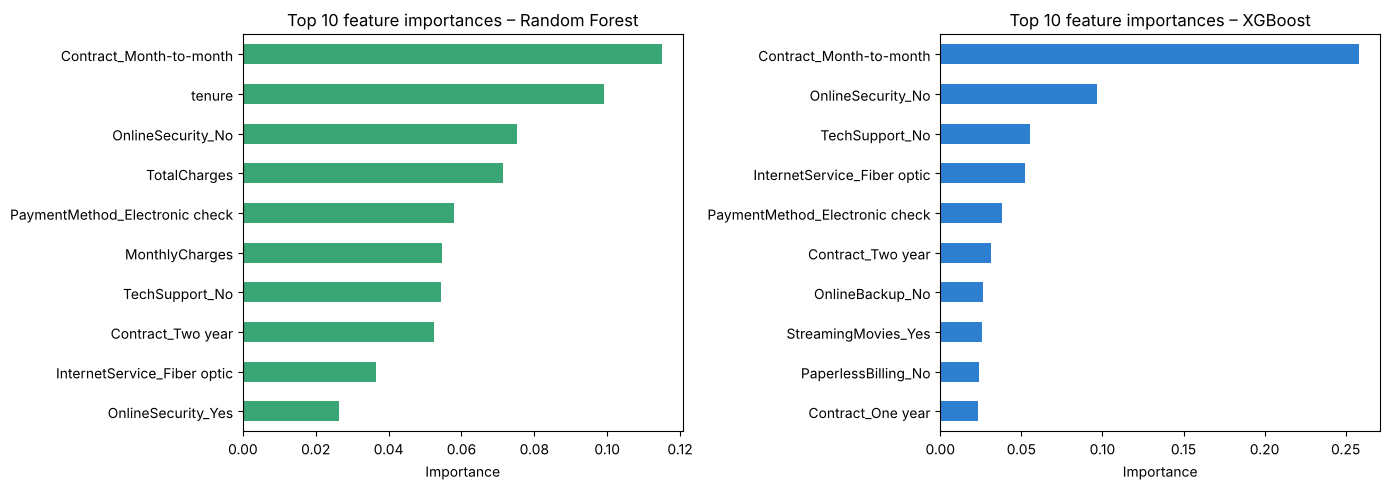

In [9]:
feat_names = rf_pipe.named_steps["pre"].get_feature_names_out()
feat_names = [f.replace("num__", "").replace("cat__", "") for f in feat_names]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (n, m) in zip(axes, models.items()):
    imp = pd.Series(m.named_steps["clf"].feature_importances_, index=feat_names).nlargest(10).sort_values()
    imp.plot(kind="barh", ax=ax, color="#2f7fd1" if n == "XGBoost" else "#3aa675")
    ax.set_title(f"Top 10 feature importances – {n}"); ax.set_xlabel("Importance")
plt.tight_layout(); plt.show()

## 7. Summary
- Both ensembles clear the **ROC-AUC > 0.80** target on the held-out set (see the scores above).
- SMOTE raises recall on the minority (churn) class compared with unweighted training, at some cost to precision, which is usually the right trade-off when missing a churner is costlier than a retention offer.
- Contract type, tenure, and charges / internet-service features rank among the strongest churn drivers, which fits the common pattern of month-to-month, short-tenure customers churning most.